<a href="https://colab.research.google.com/github/RiccardoNesca/astrostatistics_bicocca_2026/blob/main/working/working_es12.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **The transient Universe**

7) Fit the same model from before with the same priors,  but this time use nested sampling.

$y = b$, for $t<t_0$

$y = b + A\exp[-\alpha(t-t_0)]$, for $t\geq t_0$

Be careful with how you transform your parameter space into a unit hypercube for the nested sampling priors (I used `ppf` from `scipy.stats.uniform`, but there are other ways to do it)

An appropriate check on whether you have done things correctly is that the posterior samples you get from the burst analysis here should give an equivalent corner plot to the MCMC you did earlier.

In [2]:
import dynesty
import numpy as np
import matplotlib.pyplot as plt

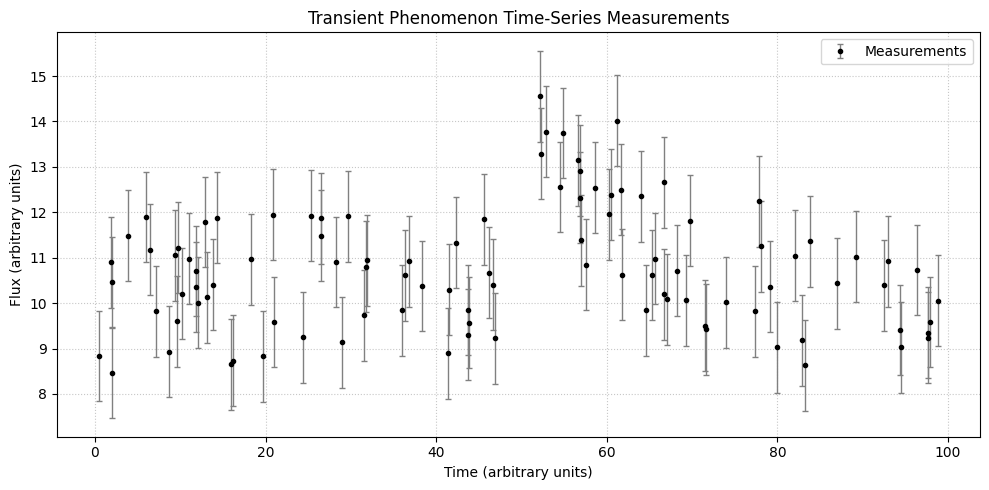

In [3]:
data = np.load('transient.npy')
time = np.array(data[:, 0])
flux = np.array(data[:, 1])
sigma = np.array(data[:, 2]) #gaussian homoschedastic

#plot
fig, ax = plt.subplots(figsize=(10, 5))

plt.plot()
ax.errorbar(
    time,
    flux,
    yerr=sigma,
    fmt='.',
    color='black',
    ecolor='gray',
    elinewidth=1,
    capsize=2,
    label='Measurements'
)

ax.set_xlabel('Time (arbitrary units)')
ax.set_ylabel('Flux (arbitrary units)')
ax.set_title('Transient Phenomenon Time-Series Measurements')
ax.grid(True, linestyle=':', alpha=0.7)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

In [4]:
def model(t,theta):
#model definition 4-D
    b,A,t0,alpha=theta
    modell = np.where(t < t0, b, b + A*np.exp(-alpha*(t-t0)))
    return modell

def logL(theta,y,t,sigma): #this parameter disposition is the one imposed by dynasty
#likelihood #need carefull normalizzation
  return -0.5*np.sum((((y-model(t,theta))**2)/(sigma**2))+np.log(2*np.pi*sigma**2))

# Define our uniform prior.
def ptform(u):
    #u unifor between 0 and 1 we need to morph it in what we need
    '''b uniform in 0,50
       A uniform in 0,50
       t0 uniform in 0,100
       lnalpha uniform in -5,5
    '''
    u1, u2, u3, u4 = u
    p1 = 50.0 * u1   #b
    p2 = 50.0 * u2   #a
    p3 = 100.0 * u3  #t0
    p4 = np.exp(5*(2*u4-1)) #alpha

    theta_prior = np.array([p1, p2, p3,p4])
    return theta_prior



Running the sample

In [5]:
# "Static" nested sampling.
labels = ['b','A','t0','alpha']
ndim = 4
sampler = dynesty.NestedSampler(logL, ptform, ndim,logl_args=[flux,time, sigma])
sampler.run_nested()
sresults = sampler.results

/tmp/ipykernel_3667/751287070.py:4: RuntimeWarning: overflow encountered in exp
  modell = np.where(t < t0, b, b + A*np.exp(-alpha*(t-t0)))
/tmp/ipykernel_3667/751287070.py:4: RuntimeWarning: overflow encountered in multiply
  modell = np.where(t < t0, b, b + A*np.exp(-alpha*(t-t0)))
 41%|████▏     | 1807/4356 [00:11<00:23, 109.58it/s, bound: 0 | nc: 131 | ncall: 18036 | eff(%): 10.019 | loglstar: -273.490 | logz: -281.882 +/-  0.123 | dlogz: 127.642 >  0.509]/tmp/ipykernel_3667/751287070.py:4: RuntimeWarning: overflow encountered in exp
  modell = np.where(t < t0, b, b + A*np.exp(-alpha*(t-t0)))
/tmp/ipykernel_3667/751287070.py:4: RuntimeWarning: overflow encountered in multiply
  modell = np.where(t < t0, b, b + A*np.exp(-alpha*(t-t0)))
 35%|███▌      | 1865/5309 [00:13<00:50, 67.88it/s, bound: 1 | nc: 7 | ncall: 18617 | eff(%): 10.018 | loglstar: -259.028 | logz: -267.154 +/-  0.120 | dlogz: 112.725 >  0.509] /tmp/ipykernel_3667/751287070.py:4: RuntimeWarning: overflow encountered i

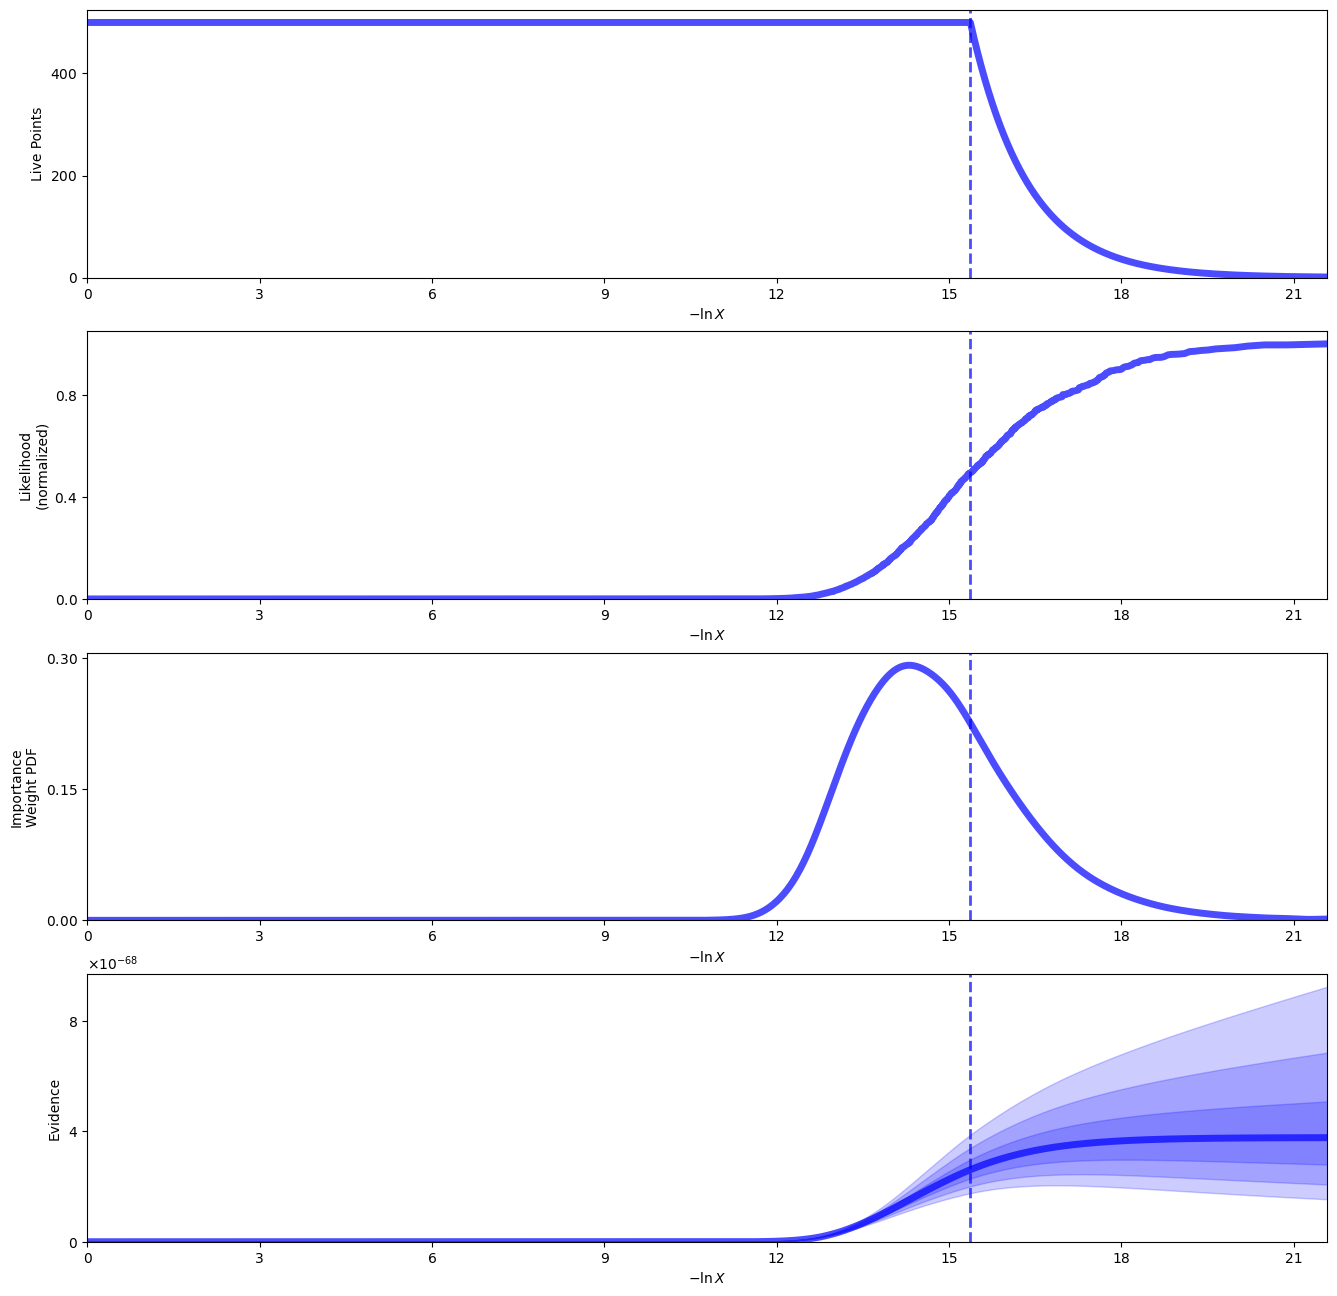

In [6]:
from dynesty import plotting as dyplot

# Plot a summary of the run.
rfig, raxes = dyplot.runplot(sresults)

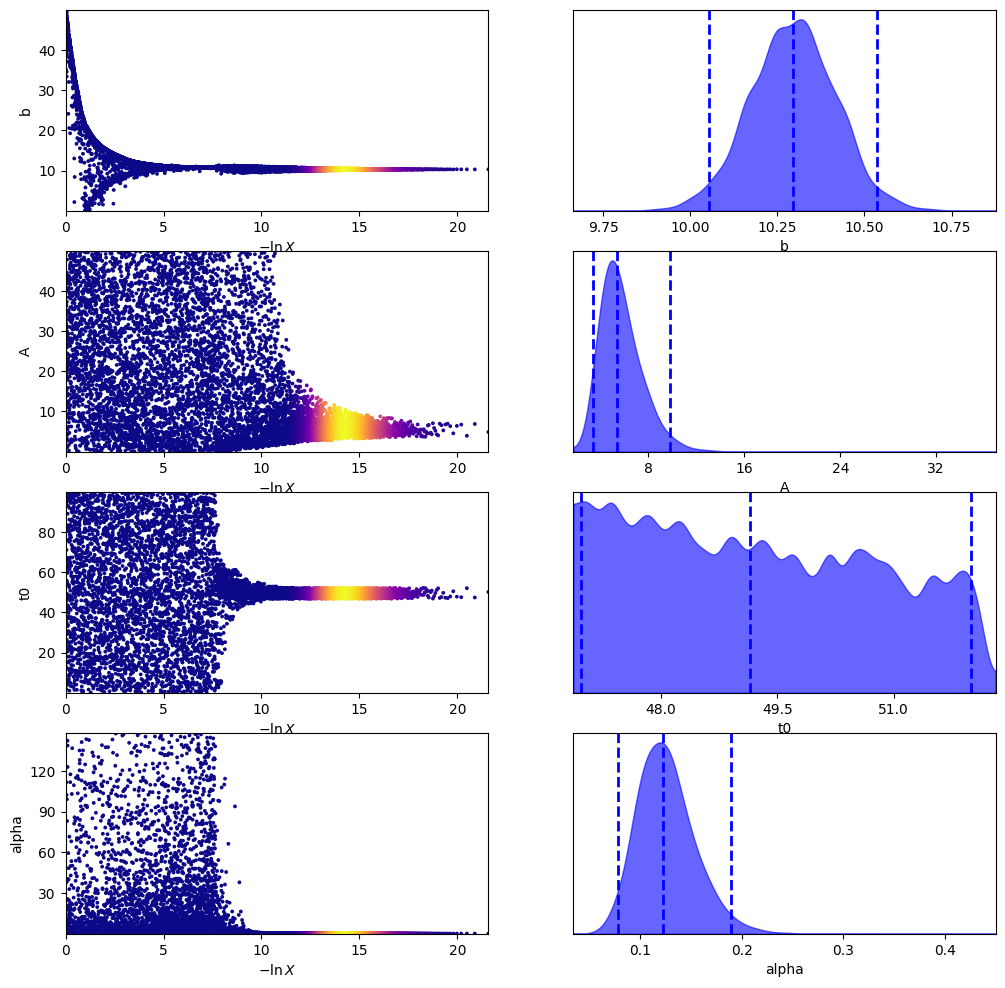

In [7]:
tfig, taxes = dyplot.traceplot(sresults,labels=labels)

CORNER PLOT

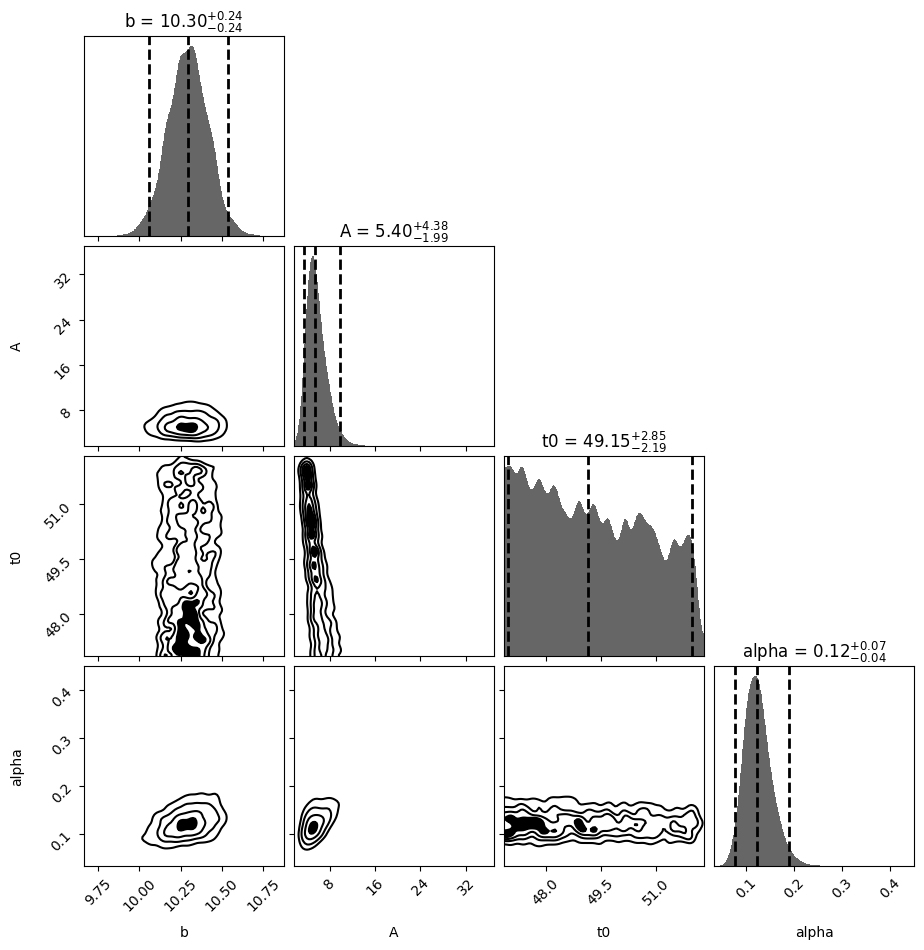

In [8]:
cfig, caxes = dyplot.cornerplot(sresults,labels=labels, show_titles=True)

PARAMETER CHECK WITH PREVIOUS LECTURE PARAMETERS

---------EMCEE PARAMETER MEDIAN AND CREDIBLE REGION------------

b

median = 10.2907
credible region 90% : 10.0938-10.4858

A

median = 5.3116
credible region 90% : 3.5911-8.6120

t0

median = 49.2247
credible region 90% : 47.0828-51.8850

alpha

median = 0.1215
credible region 90% : 0.0843-0.1758

In [9]:
from dynesty import utils as dyfunc


# Extract sampling results.
samples = sresults.samples  # samples
weights = np.exp(sresults.logwt - sresults.logz[-1])  # normalized weights

print('---------PARAMETERS------------')
# Compute credible region 90%.
for samps,label in zip(samples.T,labels):
  quantiles = [dyfunc.quantile(samps, [0.50,0.05, 0.95], weights=weights)]
  print(label + '\n: MEDIAN ' + str(quantiles[0][0]))
  print( '90% CREDIBLE REGION:' + str(quantiles[0][1])+'-'+str(quantiles[0][2]))


# Generate a new set of results with statistical+sampling uncertainties.
#results_sim = dyfunc.simulate_run(sresults)




---------PARAMETERS------------
b
: MEDIAN 10.296111184678743
90% CREDIBLE REGION:10.091547223362923-10.486113934515394
A
: MEDIAN 5.397009435499169
90% CREDIBLE REGION:3.6009602683188686-8.862302782520052
t0
: MEDIAN 49.15253887846279
90% CREDIBLE REGION:47.06876933018899-51.85112793903146
alpha
: MEDIAN 0.12284639684217329
90% CREDIBLE REGION:0.08533864231368199-0.1758064246317796


8) Another possible model that may explain the data is a Gaussian profile described by:

$y = b + A\exp[-(t-t_0)^2 / 2\sigma_W^2]$

Fit this model usign nested sampling and reasonable priors (this time is up to you to decide...)

*  The idea for the priors is that this model is gaussian peak + bkg where the previous one was background + step function signal and exponential tail.
* the background b is the same, so we can assume the same prior
* t0 and A are proportional to x and y position of the gaussian peak, this can be assumed similar to to in the previous model, we can use the same priors
* for sigma we can try to determine the width of the gaussian visually

In [35]:
def gaussian(t,theta):
#model definition 4-D
    b,A,t0,sigmaw=theta
    modell = b+A*np.exp(-((t-t0)**2)/2*sigmaw**2)
    return modell

def logL_gauss(theta,y,t,sigma):
#likelihood
  return -0.5*np.sum((((y-gaussian(t,theta))**2)/(sigma**2))+np.log(2*np.pi*sigma**2))

# Define our uniform prior.
def ptform_gauss(u):
    #u unifor between 0 and 1 we need to morph it in what we need
    '''b uniform in 0,50
       A uniform in 0,50
       t0 uniform in 0,100
       lnsigmaw uniform in -2,2
    '''
    u1, u2, u3, u4 = u
    p1 = 50.0 * u1   #b
    p2 = 50.0 * u2   #a
    p3 = 100.0 * u3  #t0
    p4 = np.exp(2*(2*u4-1)) #sigmaw

    theta_prior = np.array([p1, p2, p3,p4])
    return theta_prior



Running the sample

In [36]:
# "Static" nested sampling.
labels = ['b','A','t0','sigmaw']
ndim = 4
sampler_gauss = dynesty.NestedSampler(logL_gauss, ptform_gauss, ndim,logl_args=[flux,time, sigma])
sampler_gauss.run_nested()
sresults_gauss = sampler_gauss.results

 10%|█         | 4089/40228 [00:45<1:54:52,  5.24it/s, bound: 101 | nc: 528 | ncall: 77038 | eff(%):  5.308 | loglstar: -178.242 | logz: -186.300 +/-  0.117 | dlogz: 32.158 >  0.509]/usr/local/lib/python3.13/dist-packages/dynesty/bounding.py:706: UserWarning: The enlargement factor for the ellipsoidal bounds determined from bootstrapping is very large. If you are using uniform sampling that may mean that the sampling will be inefficient. This may be caused by a very complex posterior shape. You may consider using more livepoints or different sampler (i.e. rslice or rwalk) or alternatively disable bootstrap (bootstrap=0)
  warnings.warn(
 10%|█         | 4094/39488 [00:47<2:57:41,  3.32it/s, bound: 105 | nc: 577 | ncall: 79703 | eff(%):  5.137 | loglstar: -178.157 | logz: -186.291 +/-  0.117 | dlogz: 32.139 >  0.509]/usr/local/lib/python3.13/dist-packages/dynesty/bounding.py:706: UserWarning: The enlargement factor for the ellipsoidal bounds determined from bootstrapping is very large. 

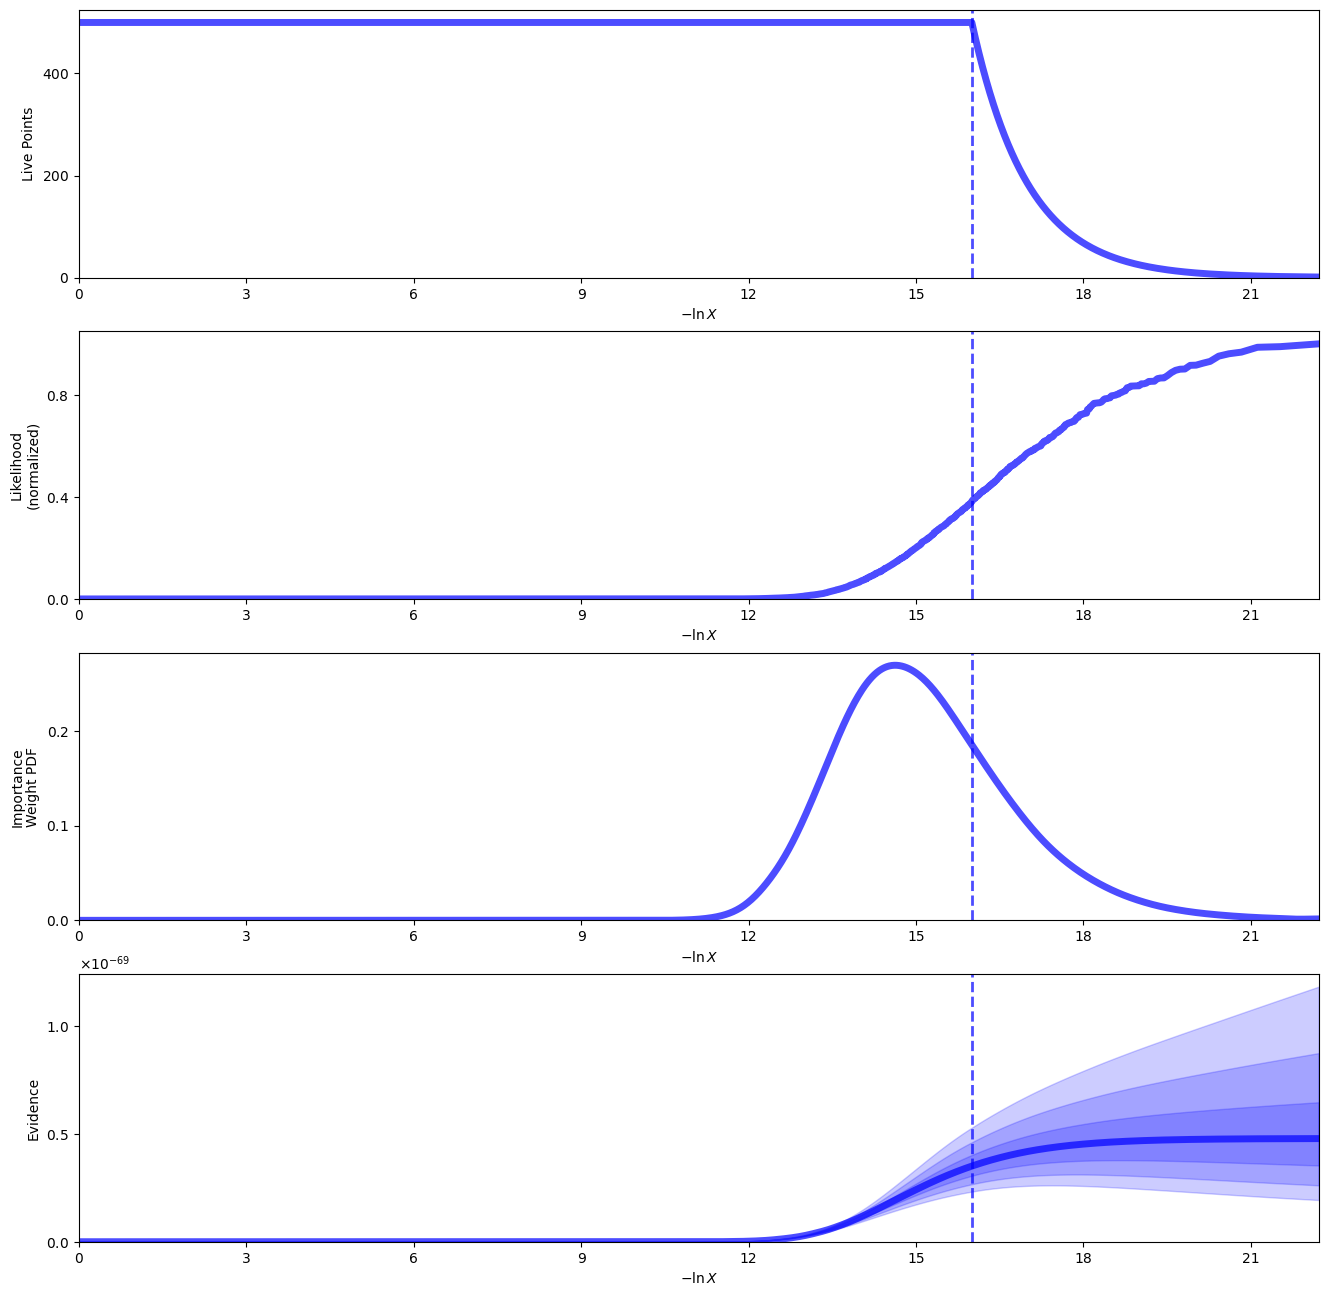

In [37]:
# Plot a summary of the run.
rfig, raxes = dyplot.runplot(sresults_gauss)

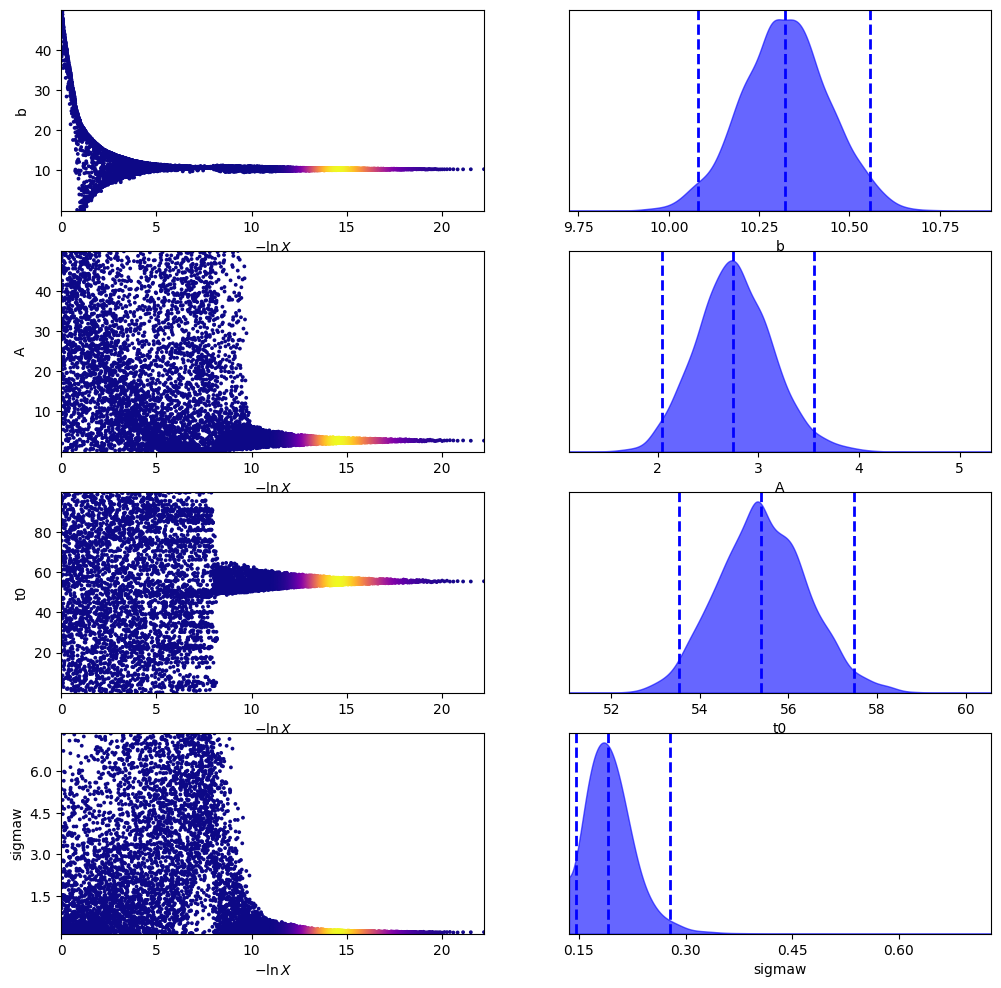

In [38]:
tfig, taxes = dyplot.traceplot(sresults_gauss,labels=labels)

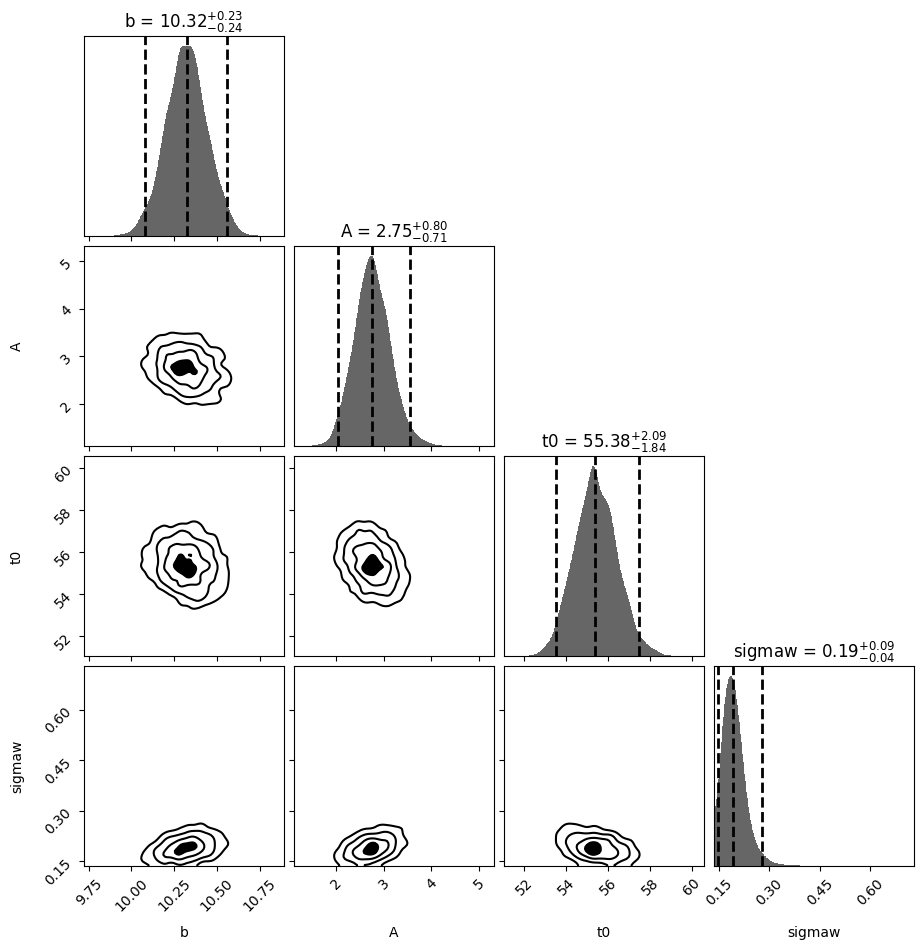

In [39]:
cfig, caxes = dyplot.cornerplot(sresults_gauss,labels=labels, show_titles=True)

In [40]:
# Extract sampling results.
samples_gauss = sresults_gauss.samples  # samples
weights_gauss = np.exp(sresults_gauss.logwt - sresults_gauss.logz[-1])  # normalized weights

print('---------PARAMETERS------------')
# Compute credible region 90%.
for samps,label in zip(samples_gauss.T,labels):
  quantiles_gauss = [dyfunc.quantile(samps, [0.50,0.05, 0.95], weights=weights_gauss)]
  print(label + '\n: MEDIAN ' + str(quantiles_gauss[0][0]))
  print( '90% CREDIBLE REGION:' + str(quantiles_gauss[0][1])+'-'+str(quantiles_gauss[0][2]))


# Generate a new set of results with statistical+sampling uncertainties.
#results_sim = dyfunc.simulate_run(sresults)


---------PARAMETERS------------
b
: MEDIAN 10.322904585391752
90% CREDIBLE REGION:10.12212152149105-10.524650840110251
A
: MEDIAN 2.7483683137979766
90% CREDIBLE REGION:2.167188728624361-3.393775629047431
t0
: MEDIAN 55.37698147116651
90% CREDIBLE REGION:53.78200358606477-57.089345193395374
sigmaw
: MEDIAN 0.1907585784221187
90% CREDIBLE REGION:0.15156833303283335-0.255277690191138


9) Unlike MCMCs, nested sampling provides the Bayesian evidence. Compute the Bayesian evidence for this Gaussian model, and for the original burst model. Which model is the favored description of the data? Express this in terms of the Jeffrey's scale.

In [50]:
evidence = np.exp(sresults.logz[-1]) #evidence burst
print("Bayesian evidence for model BURST =", evidence)
evidence_gauss= np.exp(sresults_gauss.logz[-1]) #evidence gaussian  #BOTH LOW BECAUSE I FULLY NORMALIZED THE LOGLIKELIHOOD
print("Bayesian evidence for model GAUSSIAN =", evidence_gauss)

print(f'the ratio between the BURST AND GAUSSIAN evidences is :{ evidence/evidence_gauss:.4f}')


Bayesian evidence for model BURST = 3.770164803400012e-68
Bayesian evidence for model GAUSSIAN = 4.7841544919904214e-70
the ratio between the BURST AND GAUSSIAN evidences is :78.8052


**very strong evidence in favour of the burst model**